In [1]:
!pip install -q kagglehub

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải trực tiếp bộ dữ liệu Laptop Price từ Kaggle
print("Đang kéo dữ liệu Laptop Price từ Kaggle...")
path = kagglehub.dataset_download("muhammetvarl/laptop-price")

# 2. Tự động tìm file .csv trong thư mục vừa tải
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
file_path = os.path.join(path, csv_file)

# 3. Đọc file CSV (LƯU Ý: bắt buộc dùng encoding='latin-1' để tránh lỗi ký tự đặc biệt)
df_laptop = pd.read_csv(file_path, encoding='latin-1')

print(f"Đã nạp thành công: {df_laptop.shape[0]:,} dòng và {df_laptop.shape[1]} cột.")
display(df_laptop.head(5))

print("\n--- SOI KIỂU DỮ LIỆU TỪNG CỘT ---")
df_laptop.info()

Đang kéo dữ liệu Laptop Price từ Kaggle...
Using Colab cache for faster access to the 'laptop-price' dataset.
Đã nạp thành công: 1,303 dòng và 13 cột.


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60



--- SOI KIỂU DỮ LIỆU TỪNG CỘT ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


In [2]:
df_clean = df_laptop.copy()

# 1. Xóa các cột rác / quá nhiều giá trị riêng lẻ (High Cardinality)
# laptop_ID chỉ là số thứ tự; Product có hàng trăm tên máy riêng lẻ -> bỏ để tránh làm loãng mô hình
df_clean = df_clean.drop(columns=['laptop_ID', 'Product'])

# 2. Làm sạch cột số bị dính chữ bằng Vectorization (nhanh hơn .apply() gấp chục lần)
df_clean['Ram_GB'] = df_clean['Ram'].str.replace('GB', '', regex=False).astype(int)
df_clean['Weight_kg'] = df_clean['Weight'].str.replace('kg', '', regex=False).astype(float)

# 3. Trích xuất đặc trưng "ăn tiền" từ màn hình (ScreenResolution) & Ổ cứng (Memory)
df_clean['Touchscreen'] = df_clean['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)
df_clean['IPS_Panel'] = df_clean['ScreenResolution'].str.contains('IPS', case=False).astype(int)
df_clean['Has_SSD'] = df_clean['Memory'].str.contains('SSD', case=False).astype(int)

# 4. Gom nhóm dòng chip CPU (thay vì giữ nguyên hàng trăm mã chip chi tiết)
def extract_cpu_brand(text):
    if 'Intel Core i7' in text: return 'Intel Core i7'
    elif 'Intel Core i5' in text: return 'Intel Core i5'
    elif 'Intel Core i3' in text: return 'Intel Core i3'
    elif 'Intel' in text: return 'Other Intel'
    else: return 'AMD / Khac'

df_clean['Cpu_Brand'] = df_clean['Cpu'].apply(extract_cpu_brand)

# 5. Gom nhóm hãng card đồ họa GPU (chỉ lấy từ đầu tiên: Intel, Nvidia, AMD)
df_clean['Gpu_Brand'] = df_clean['Gpu'].str.split().str[0]

# 6. Xóa các cột chuỗi thô đã bóc tách xong & xóa dòng trùng lặp (nếu có)
df_clean = df_clean.drop(columns=['Ram', 'Weight', 'ScreenResolution', 'Cpu', 'Memory', 'Gpu'])
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Sau khi bóc tách & làm sạch: {df_clean.shape[0]:,} dòng và {df_clean.shape[1]} cột sạch.")
display(df_clean.head(5))

Sau khi bóc tách & làm sạch: 1,273 dòng và 12 cột sạch.


,Company,TypeName,Inches,OpSys,Price_euros,Ram_GB,Weight_kg,Touchscreen,IPS_Panel,Has_SSD,Cpu_Brand,Gpu_Brand
0,Apple,Ultrabook,13.3,macOS,1339.69,8,1.37,0,1,1,Intel Core i5,Intel
1,Apple,Ultrabook,13.3,macOS,898.94,8,1.34,0,0,0,Intel Core i5,Intel
2,HP,Notebook,15.6,No OS,575.00,8,1.86,0,0,1,Intel Core i5,Intel
3,Apple,Ultrabook,15.4,macOS,2537.45,16,1.83,0,1,1,Intel Core i7,AMD
4,Apple,Ultrabook,13.3,macOS,1803.60,8,1.37,0,1,1,Intel Core i5,Intel


In [6]:
# 1. Mã hóa toàn bộ các cột chữ còn lại thành cột nhị phân 0/1
# drop_first=True để tránh Bẫy biến giả (Đa cộng tuyến hoàn hảo)
cat_cols = ['Company', 'TypeName', 'OpSys', 'Cpu_Brand', 'Gpu_Brand']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)

# 2. Tách biến đầu vào X và biến mục tiêu y (Giá bán tính bằng Euro)
X = df_encoded.drop(columns=['Price_euros'])
y = df_encoded['Price_euros']

# 3. Chia tập 80% Train - 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Khởi tạo và Huấn luyện mô hình Hồi quy tuyến tính đa biến
model_laptop = LinearRegression()
model_laptop.fit(X_train, y_train)

print(f"Tổng số đặc trưng đầu vào sau mã hóa: {X.shape[1]} biến")
print(f"Tập Train: {len(X_train):,} máy | Tập Test: {len(X_test):,} máy")
print(f"Hệ số chặn (Intercept): {model_laptop.intercept_:.2f} EUR")
print("==> Huấn luyện mô hình hoàn tất!")

Tổng số đặc trưng đầu vào sau mã hóa: 44 biến
Tập Train: 1,018 máy | Tập Test: 255 máy
Hệ số chặn (Intercept): -150.39 EUR
==> Huấn luyện mô hình hoàn tất!


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN GIÁ LAPTOP ===
Mean Squared Error (MSE):  137,518.22
Root MSE (RMSE):           370.83 EUR (Sai số trung bình thực tế)
R² Score:                  0.7292 (Giải thích được 72.92% sự biến thiên giá)


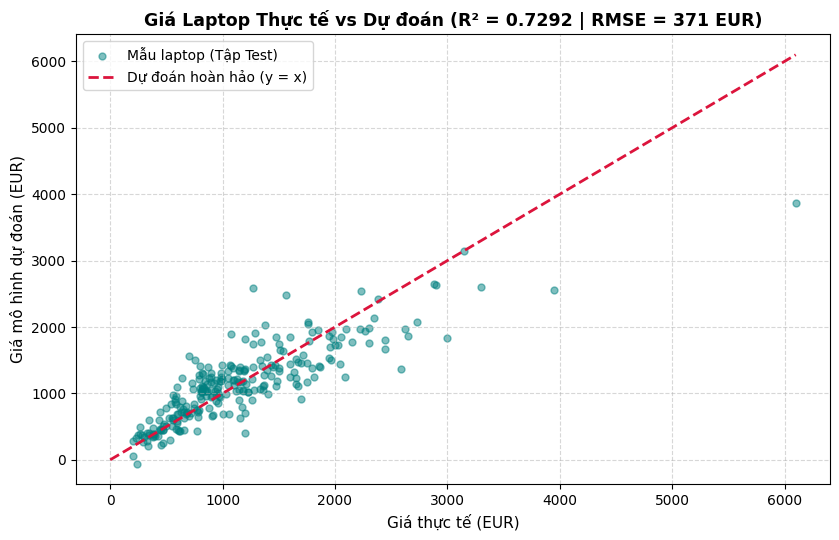

In [8]:
# 1. Dự đoán giá laptop trên tập Test
y_pred = model_laptop.predict(X_test)

# 2. Tính các chỉ số đánh giá
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN GIÁ LAPTOP ===")
print(f"Mean Squared Error (MSE):  {mse:,.2f}")
print(f"Root MSE (RMSE):           {rmse:,.2f} EUR (Sai số trung bình thực tế)")
print(f"R² Score:                  {r2:.4f} (Giải thích được {r2*100:.2f}% sự biến thiên giá)")

# 3. Vẽ biểu đồ so sánh Giá thực tế vs Giá dự đoán
plt.figure(figsize=(8.5, 5.5))
plt.scatter(y_test, y_pred, color='teal', alpha=0.5, s=25, label='Mẫu laptop (Tập Test)')

max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], color='crimson', linestyle='--', lw=2, label='Dự đoán hoàn hảo (y = x)')

plt.title(f'Giá Laptop Thực tế vs Dự đoán (R² = {r2:.4f} | RMSE = {rmse:.0f} EUR)', fontsize=12.5, fontweight='bold')
plt.xlabel('Giá thực tế (EUR)', fontsize=11)
plt.ylabel('Giá mô hình dự đoán (EUR)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()